# 04. Backtest results

Pseudo-real-time backtest: 76 target quarters from 2006Q1 to 2026Q2 (excluding 2020Q1-2021Q2) at
horizons -1 to 2, and 27 quarters from 2018Q3 at horizon 3 (before mid-2018 the first estimate was
published within a month of the quarter, so there was nothing left to nowcast). Every model is
re-tuned and re-estimated at each of the 361 origins using only data published by then.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from nowcast.config import HORIZON_LABELS

In [2]:
rmse = pd.read_csv(T / "rmse_first_estimate.csv", index_col=0); rmse.columns = rmse.columns.astype(int)
rmse.rename(columns=HORIZON_LABELS).style.format("{:.3f}").highlight_min(axis=0, color="#c7e9c0")

,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
Mean,0.556,0.550,0.549,0.549,0.378
AR,0.629,0.495,0.485,0.504,0.468
Bridge,0.590,0.476,0.467,0.364,0.320
OLS (all),0.601,0.550,0.562,0.503,0.388
Ridge,0.559,0.477,0.484,0.453,0.383
Lasso,0.559,0.528,0.522,0.498,0.405
Elastic net,0.549,0.495,0.497,0.485,0.414
Adaptive lasso,0.567,0.535,0.566,0.512,0.475
Group lasso,0.568,0.475,0.493,0.474,0.354


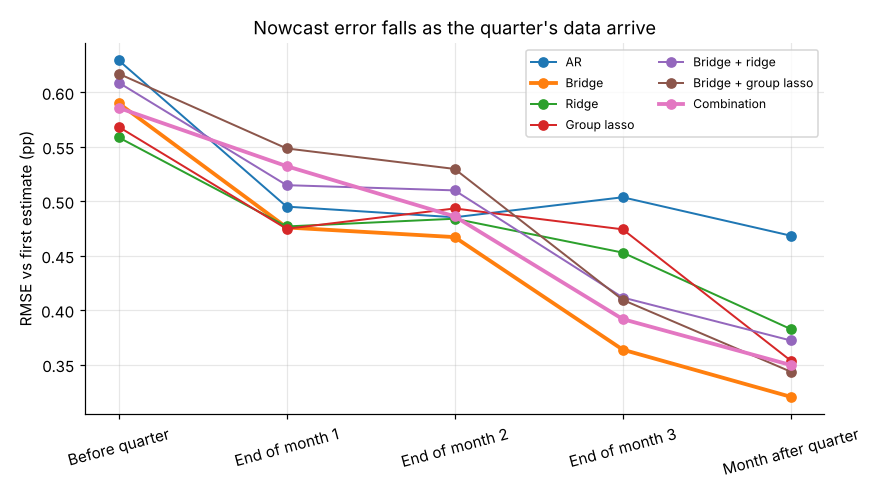

In [3]:
display(Image(FIG / 'rmse_by_horizon.png'))

## Significance: Diebold-Mariano tests (Harvey-Leybourne-Newbold correction)

In [4]:
dm = pd.read_csv(T / "dm_vs_ar.csv")
dmb = pd.read_csv(T / "dm_vs_bridge.csv")
show = lambda d: d.pivot(index="model", columns="h", values="rel_rmse").round(3).astype(str) + \
    d.pivot(index="model", columns="h", values="p_value").map(
        lambda p: "" if pd.isna(p) else ("**" if p < 0.05 else "*" if p < 0.1 else ""))
print("Relative RMSE vs AR (below 1 = better). ** p<0.05, * p<0.1")
display(show(dm).rename(columns=HORIZON_LABELS))
print("Relative RMSE vs the bridge equation")
display(show(dmb).rename(columns=HORIZON_LABELS))

Relative RMSE vs AR (below 1 = better). ** p<0.05, * p<0.1


h,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
Adaptive lasso,0.901,1.081,1.166,1.016,1.013
Bridge,0.937,0.961,0.962,0.722**,0.684**
Bridge + elastic net,0.99,1.211,1.059,0.842,0.829
Bridge + factors,0.947,0.97,0.943,0.713**,0.714**
Bridge + group lasso,0.98,1.108,1.091,0.813,0.733**
Bridge + lasso,0.97,1.231,1.118,0.829,0.77**
Bridge + ridge,0.967,1.04,1.051,0.817*,0.795**
Combination,0.931,1.075,1.002,0.778*,0.746**
Elastic net,0.873,0.999,1.024,0.963,0.883


Relative RMSE vs the bridge equation


h,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
AR,1.067,1.04,1.039,1.385**,1.462**
Adaptive lasso,0.961,1.124,1.212,1.407**,1.481*
Bridge + elastic net,1.056,1.26**,1.1,1.166*,1.211
Bridge + factors,1.01,1.009,0.98,0.987,1.044
Bridge + group lasso,1.046,1.152**,1.134,1.126,1.072
Bridge + lasso,1.034,1.28**,1.162*,1.147,1.125
Bridge + ridge,1.032,1.082,1.092,1.132*,1.161
Combination,0.993,1.118**,1.041,1.077,1.091
Elastic net,0.931,1.039,1.064,1.333**,1.291*


In [5]:
best = rmse.idxmin()
for h in rmse.columns:
    print(f"{HORIZON_LABELS[h]:>24}: best {best[h]:<22} {rmse.loc[best[h], h]:.3f}"
          f"   bridge {rmse.loc['Bridge', h]:.3f}   AR {rmse.loc['AR', h]:.3f}   mean {rmse.loc['Mean', h]:.3f}")

          Before quarter: best Factor                 0.549   bridge 0.590   AR 0.629   mean 0.556
          End of month 1: best Factor                 0.460   bridge 0.476   AR 0.495   mean 0.550
          End of month 2: best Bridge + factors       0.458   bridge 0.467   AR 0.485   mean 0.549
          End of month 3: best Bridge + factors       0.359   bridge 0.364   AR 0.504   mean 0.549
     Month after quarter: best Bridge                 0.320   bridge 0.320   AR 0.468   mean 0.378


## By period

In [6]:
for h in [0, 2, 3]:
    t = pd.read_csv(T / f"rmse_by_period_h{h}.csv", index_col=0)
    print(HORIZON_LABELS[h]); display(t.round(3))

End of month 1


,2006-2009 (financial crisis),2010-2019,2021Q3-2026 (post-COVID)
model,,,
Mean,0.920,0.390,0.407
AR,0.622,0.460,0.445
Bridge,0.497,0.436,0.532
OLS (all),0.603,0.471,0.643
Ridge,0.616,0.428,0.441
Lasso,0.704,0.471,0.470
Elastic net,0.649,0.459,0.413
Adaptive lasso,0.620,0.509,0.511
Group lasso,0.623,0.436,0.406


End of month 3


,2006-2009 (financial crisis),2010-2019,2021Q3-2026 (post-COVID)
model,,,
Mean,0.920,0.390,0.405
AR,0.641,0.434,0.508
Bridge,0.361,0.360,0.373
OLS (all),0.491,0.450,0.602
Ridge,0.498,0.423,0.472
Lasso,0.619,0.472,0.438
Elastic net,0.595,0.454,0.445
Adaptive lasso,0.548,0.477,0.548
Group lasso,0.545,0.436,0.486


Month after quarter


,2006-2009 (financial crisis),2010-2019,2021Q3-2026 (post-COVID)
model,,,
Mean,NaN,0.288,0.405
AR,NaN,0.316,0.511
Bridge,NaN,0.125,0.365
OLS (all),NaN,0.239,0.429
Ridge,NaN,0.214,0.426
Lasso,NaN,0.242,0.448
Elastic net,NaN,0.275,0.452
Adaptive lasso,NaN,0.307,0.521
Group lasso,NaN,0.245,0.384


## Nowcasts over time (end of quarter)

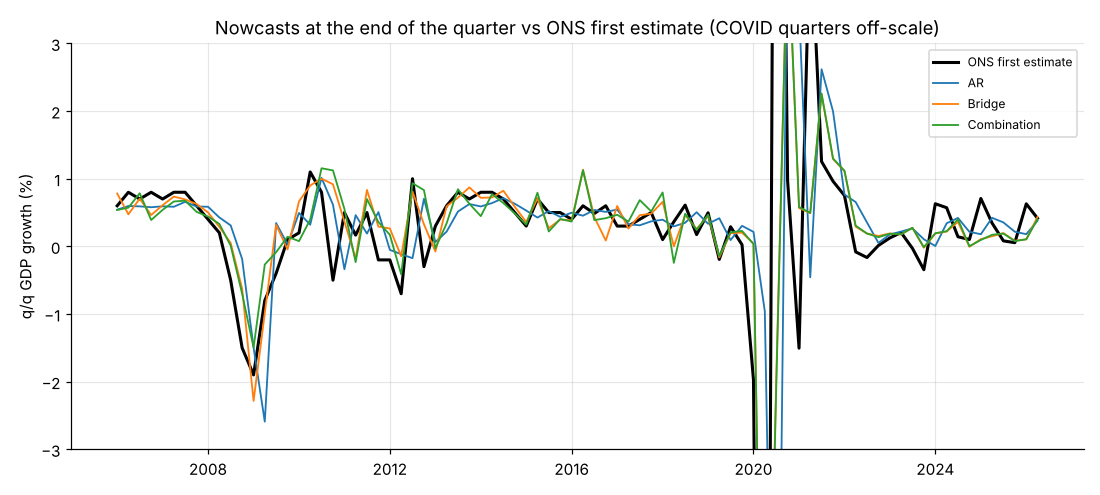

In [7]:
display(Image(FIG / 'nowcast_vs_first_h2.png'))

## Against the latest estimate

In [8]:
rl = pd.read_csv(T / "rmse_latest_estimate.csv", index_col=0); rl.columns = rl.columns.astype(int)
rl.rename(columns=HORIZON_LABELS).style.format("{:.3f}").highlight_min(axis=0, color="#c7e9c0")

,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
Mean,0.641,0.636,0.635,0.635,0.427
AR,0.733,0.613,0.572,0.580,0.366
Bridge,0.683,0.570,0.519,0.427,0.255
OLS (all),0.608,0.571,0.583,0.525,0.320
Ridge,0.582,0.518,0.521,0.487,0.304
Lasso,0.586,0.567,0.569,0.546,0.302
Elastic net,0.585,0.536,0.556,0.530,0.312
Adaptive lasso,0.594,0.560,0.593,0.530,0.384
Group lasso,0.596,0.540,0.533,0.515,0.265


## Interval calibration
Empirical 80% intervals from each model's own past errors (last 40 quarters, at least 12).

In [9]:
cov = pd.read_csv(T / "interval_coverage_80.csv", index_col=0); cov.columns = cov.columns.astype(int)
cov.rename(columns=HORIZON_LABELS).round(2)

,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
Mean,0.83,0.83,0.83,0.83,0.93
AR,0.76,0.81,0.79,0.78,0.71
Bridge,0.79,0.81,0.79,0.83,0.57
OLS (all),0.83,0.79,0.71,0.71,0.71
Ridge,0.84,0.75,0.79,0.76,0.64
Lasso,0.79,0.81,0.83,0.84,0.79
Elastic net,0.78,0.83,0.83,0.81,0.79
Adaptive lasso,0.79,0.81,0.79,0.79,0.71
Group lasso,0.81,0.83,0.76,0.75,0.71


## Including COVID
2020Q2 GDP fell by about 19%. Including 2020Q1-2021Q2 in the evaluation, RMSEs are dominated by six
quarters; the table is shown for completeness.

In [10]:
rc = pd.read_csv(T / "rmse_first_estimate_incl_covid.csv", index_col=0); rc.columns = rc.columns.astype(int)
rc.rename(columns=HORIZON_LABELS).round(2)

,Before quarter,End of month 1,End of month 2,End of month 3,Month after quarter
model,,,,,
Mean,2.95,2.95,2.95,2.95,4.58
AR,3.34,3.03,3.72,3.70,5.81
Bridge,3.20,3.88,3.35,2.41,2.72
OLS (all),3.35,3.45,3.30,2.69,3.85
Ridge,3.10,3.12,3.04,2.70,3.97
Lasso,3.32,3.22,3.24,3.20,4.00
Elastic net,3.23,3.19,3.15,2.89,4.09
Adaptive lasso,3.46,3.33,3.15,2.97,4.05
Group lasso,3.26,3.14,3.32,2.85,3.62
